# Model: what drives winpercent?

OLS fitted with numpy/scipy (src/ols.py) on 83 candies (coins removed).

In [1]:
import sys
from pathlib import Path
sys.path.append("..")
from src.load_data import download_data, load_data
from src.features import add_gummy, remove_coins, build_features
from src.ols import fit_ols, contrast, predict

import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

FIG_DIR = Path("../figures")
FIG_DIR.mkdir(exist_ok=True)

download_data()
df = add_gummy(remove_coins(load_data()))
X, y = build_features(df)

In [2]:
# checks the hand-written OLS against an independent implementation (scipy.stats.linregress)
one = fit_ols(df[["chocolate"]], y)
row = one["table"].loc["chocolate"]
lr = stats.linregress(df["chocolate"], y)

pd.DataFrame(
    {
        "fit_ols": [row["coef"], row["se"], row["p"], one["r2"]],
        "linregress": [lr.slope, lr.stderr, lr.pvalue, lr.rvalue ** 2],
    },
    index=["coef", "se", "p_value", "r2"],
).round(3)

,fit_ols,linregress
coef,18.651,18.651
se,2.539,2.539
p_value,0.000,0.000
r2,0.400,0.400


In [3]:
res = fit_ols(X, y)

print(f"n = {len(y)}, dof = {res['dof']}, r2 = {res['r2']}, adj_r2 = {res['adj_r2']}")
res["table"]

n = 83, dof = 71, r2 = 0.5635738412989566, adj_r2 = 0.49595852093682313


,coef,se,t,p,ci_low,ci_high
const,29.561707,4.888003,6.047808,6.193475e-08,19.815305,39.308108
chocolate,21.693168,4.035025,5.376217,9.226617e-07,13.647557,29.738779
fruity,9.248543,4.070965,2.271831,2.612860e-02,1.131270,17.365816
caramel,2.634534,3.605359,0.730727,4.673504e-01,-4.554348,9.823415
peanutyalmondy,10.079465,3.524018,2.860220,5.555705e-03,3.052773,17.106156
nougat,1.809136,5.501625,0.328837,7.432472e-01,-9.160793,12.779064
crispedricewafer,8.568665,5.148264,1.664379,1.004442e-01,-1.696682,18.834013
hard,-2.819096,3.611281,-0.780636,4.376115e-01,-10.019786,4.381593
bar,-1.129978,4.792542,-0.235778,8.142834e-01,-10.686036,8.426079
pluribus,-1.350723,3.147040,-0.429204,6.690742e-01,-7.625743,4.924297


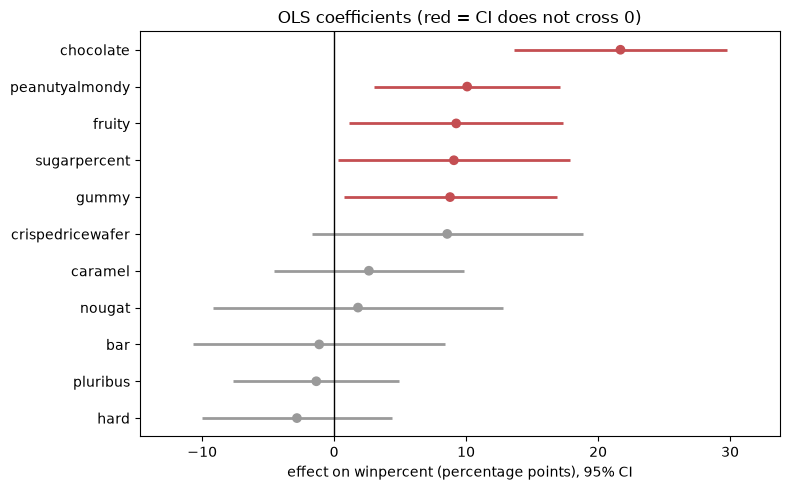

In [4]:
coefs = res["table"].drop(index="const").sort_values("coef")
significant = (coefs["ci_low"] > 0) | (coefs["ci_high"] < 0)
colors = significant.map({True: "#C44E52", False: "#9A9A9A"})

fig, ax = plt.subplots(figsize=(8, 5))
ypos = range(len(coefs))
ax.hlines(ypos, coefs["ci_low"], coefs["ci_high"], colors=colors, lw=2)
ax.scatter(coefs["coef"], ypos, color=colors, zorder=3)
ax.axvline(0, color="black", lw=1)
ax.set_yticks(list(ypos))
ax.set_yticklabels(coefs.index)
ax.set_xlabel("effect on winpercent (percentage points), 95% CI")
ax.set_title("OLS coefficients (red = CI does not cross 0)")
ax.margins(x=0.1)
fig.tight_layout()
fig.savefig(FIG_DIR / "06_coef_plot.png", dpi=150)
plt.show()

In [5]:
# segment overlap: cookie candies vs. chocolate, gummies vs. fruity
display(pd.crosstab(df["crispedricewafer"], df["chocolate"], margins=True))
pd.crosstab(df["gummy"], df["fruity"], margins=True)

chocolate,0,1,All
crispedricewafer,,,
0,46,30,76
1,0,7,7
All,46,37,83


fruity,0,1,All
gummy,,,
0,44,28,72
1,1,10,11
All,45,38,83


- **Model fit:** R² = 0.56, adj. R² = 0.50 (in-sample). The model explains about half of the variance in win percentage. I think this is enough to see which attributes matter, but not enough to predict one candy precisely.
- **Coefficients:** how many pp the win percentage changes when the candy has the attribute, if everything else is the same.
- **Chocolate:** the biggest effect, +21.7 pp, 95% CI [13.6, 29.7].
- **Second group:** peanut/almond (+10.1), fruity (+9.2), sugar (+9.1, least vs. most sugary) and gummy (+8.8) are all around +9–10 pp. Their CIs overlap, so I don't rank them.
- **Cookie vs. gummy:** almost the same (+8.6 vs +8.8). Cookie is not significant (p = 0.10), but there are only 7 cookie candies, so the data can't tell if the effect is zero or not. I test the difference directly in the next section.

## Cookie vs. gummy: difference test

In [6]:
# cookie minus gummy, both other attributes held constant
pd.Series(contrast(res, {"crispedricewafer": 1, "gummy": -1}))

est        -0.216566
se          6.543351
t          -0.033097
p           0.973690
ci_low    -13.263639
ci_high    12.830506
dtype: float64

- The difference between cookie and gummy is close to zero, −0.2 pp, p = 0.97.
- The 95% CI is wide, between −13 and +13, so the data cannot tell which one is better. Texture alone doesn't decide it.
- All cookie candies have chocolate and none of the gummies do (see profiles). So I measure the two influences in different product categories. I can only compare them if I assume both influences would be the same in both categories (additive model).

## Robustness: strict gummy definition, model without Starburst

In [7]:
# refit the model with the strict gummy definition and without the largest outlier
df_strict = add_gummy(remove_coins(load_data()), include_borderline=False)
df_no_starburst = df[df["competitorname"] != "Starburst"]

models = {
    "main": res,
    "strict gummy": fit_ols(*build_features(df_strict)),
    "no Starburst": fit_ols(*build_features(df_no_starburst)),
}

# chocolate cookie bar minus fruity gummy (pluribus), same profiles as in the "Full product profiles" section
profile_diff = {"chocolate": 1, "crispedricewafer": 1, "bar": 1, "fruity": -1, "gummy": -1, "pluribus": -1}

rows = {}
for name, m in models.items():
    t = m["table"]
    diff = contrast(m, {"crispedricewafer": 1, "gummy": -1})
    prof = contrast(m, profile_diff)
    rows[name] = {
        "n": len(m["resid"]),
        "cookie": t.loc["crispedricewafer", "coef"],
        "cookie_p": t.loc["crispedricewafer", "p"],
        "gummy": t.loc["gummy", "coef"],
        "gummy_p": t.loc["gummy", "p"],
        "fruity": t.loc["fruity", "coef"],
        "cookie_minus_gummy": diff["est"],
        "diff_p": diff["p"],
        "profile_diff": prof["est"],
        "profile_p": prof["p"],
    }
pd.DataFrame(rows).T

,n,cookie,cookie_p,gummy,gummy_p,fruity,cookie_minus_gummy,diff_p,profile_diff,profile_p
main,83.0,8.568665,0.100444,8.785232,0.033333,9.248543,-0.216566,0.973690,12.448803,0.025471
strict gummy,83.0,8.536052,0.107985,6.489178,0.163911,10.564907,2.046874,0.770511,12.697763,0.041845
no Starburst,82.0,8.531556,0.085160,10.850086,0.006989,7.764359,-2.318530,0.711775,12.552973,0.017892


- I checked the result with two other versions: a stricter gummy definition (only the 7 certain gummies) and a model without Starburst (the largest residual).
- The gummy effect changes between +6.5 and +10.9 pp, and with the strict definition it is not significant (p = 0.16). So its exact size is uncertain. Cookie stays around +8.5 pp.
- The cookie − gummy difference stays close to zero in all three models (p ≥ 0.71).
- The full profile difference (chocolate cookie bar vs. fruity gummy, see profiles) stays between +12.4 and +12.7 pp, p < 0.05.
- So the main conclusion does not depend on how I define gummy or on Starburst.

## Full product profiles

In [8]:
# no candy is both gummy and chocolate; only one is both fruity and chocolate
display(pd.crosstab(df["gummy"], df["chocolate"], margins=True))
pd.crosstab(df["fruity"], df["chocolate"], margins=True)

chocolate,0,1,All
gummy,,,
0,35,37,72
1,11,0,11
All,46,37,83


chocolate,0,1,All
fruity,,,
0,9,36,45
1,37,1,38
All,46,37,83


In [9]:
# typical product of each segment: attributes that most candies in the segment have
for seg in ["crispedricewafer", "gummy"]:
    share = df.loc[df[seg] == 1, X.columns.drop("sugarpercent")].mean()
    print(seg, "->", list(share[share > 0.5].index))

crispedricewafer -> ['chocolate', 'crispedricewafer', 'bar']
gummy -> ['fruity', 'pluribus', 'gummy']


In [10]:
# sugar is set to the median of all candies, so only the product type differs
sugar = df["sugarpercent"].median()
profiles = {
    "chocolate cookie bar": {"chocolate": 1, "crispedricewafer": 1, "bar": 1, "sugarpercent": sugar},
    "fruity gummy (pluribus)": {"fruity": 1, "gummy": 1, "pluribus": 1, "sugarpercent": sugar},
}
pred = pd.DataFrame({name: predict(res, p) for name, p in profiles.items()}).T
print(f"sugarpercent = {sugar}")
pred[["est", "ci_low", "ci_high"]]

sugarpercent = 0.465


,est,ci_low,ci_high
chocolate cookie bar,62.913286,54.244654,71.581917
fruity gummy (pluribus),50.464482,44.065206,56.863759


In [11]:
# difference of the two full profiles (sugar cancels out)
cookie_bar = profiles["chocolate cookie bar"]
gummy_pack = profiles["fruity gummy (pluribus)"]
w = {k: cookie_bar.get(k, 0) - gummy_pack.get(k, 0) for k in set(cookie_bar) | set(gummy_pack)}
pd.Series(contrast(res, w))

est        12.448803
se          5.454539
t           2.282283
p           0.025471
ci_low      1.572761
ci_high    23.324846
dtype: float64

In [12]:
# third profile, same rule: attributes that most peanut/almond candies have
share = df.loc[df["peanutyalmondy"] == 1, X.columns.drop("sugarpercent")].mean()
peanut = {col: 1 for col in share[share > 0.5].index}
peanut["sugarpercent"] = sugar
print("peanutyalmondy ->", list(share[share > 0.5].index))
pd.Series(predict(res, peanut)).round(3)

peanutyalmondy -> ['chocolate', 'peanutyalmondy']


est        65.554
se          3.976
t          16.486
p           0.000
ci_low     57.626
ci_high    73.483
dtype: float64

In [13]:
# peanut profile minus chocolate cookie bar (sugar cancels out)
w = {k: peanut.get(k, 0) - cookie_bar.get(k, 0) for k in set(peanut) | set(cookie_bar)}
pd.Series(contrast(res, w))

est         2.640778
se          6.005508
t           0.439726
p           0.661471
ci_low     -9.333865
ci_high    14.615420
dtype: float64

- All 7 cookie candies have chocolate and none of the gummies do. There is no chocolate gummy in the data, so I cannot say anything about that combination.
- To compare whole products, I built a typical profile for both. A profile has the attributes that most candies in the segment have. Cookie: chocolate + crisped rice/wafer + bar. Gummy: fruity + gummy + pluribus. For sugar I used the median of all candies in both cases.
- The chocolate cookie bar gets 62.9 [54.2, 71.6] and the fruity gummy gets 50.5 [44.1, 56.9].
- The difference is +12.4 pp for the cookie bar, 95% CI [1.6, 23.3], p = 0.03. So the cookie bar is significantly better.
- Almost all of this comes from chocolate vs. fruity (21.69 − 9.25 = 12.44). The texture effects nearly cancel out.
- I also checked a chocolate + peanut/almond profile (bar is exactly half of these candies, so it is left out): 65.6 [57.6, 73.5]. Compared to the chocolate cookie bar it is +2.6 pp, 95% CI [−9.3, 14.6], p = 0.66. So inside chocolate the data cannot choose between cookie and peanut.
- These CIs are for an average product with this profile. One new product can vary more, because the model misses by about 10.5 pp on a single candy.

## Diagnostics

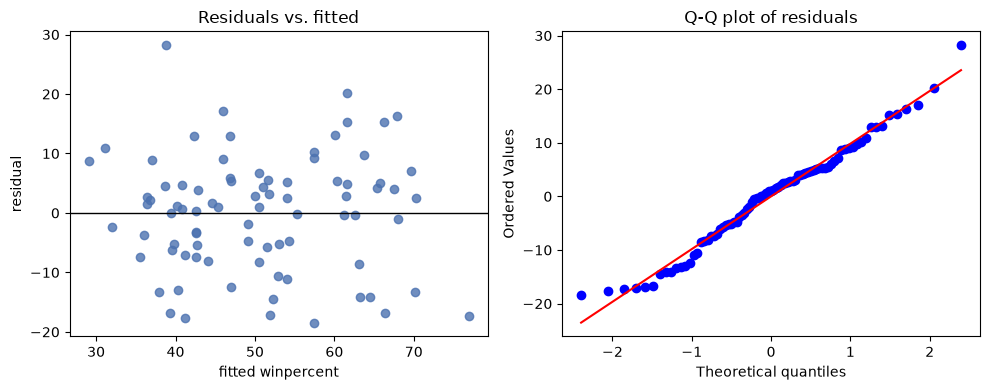

residual std = 10.471097273570352
Shapiro-Wilk p = 0.2857630478259606


In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.scatter(res["fitted"], res["resid"], color="#4C72B0", alpha=0.8)
ax1.axhline(0, color="black", lw=1)
ax1.set_xlabel("fitted winpercent")
ax1.set_ylabel("residual")
ax1.set_title("Residuals vs. fitted")

stats.probplot(res["resid"], dist="norm", plot=ax2)
ax2.set_title("Q-Q plot of residuals")

fig.tight_layout()
fig.savefig(FIG_DIR / "07_residual_diagnostics.png", dpi=150)
plt.show()

print(f"residual std = {res['sigma2'] ** 0.5}")
print(f"Shapiro-Wilk p = {stats.shapiro(res['resid']).pvalue}")

In [15]:
# fitted/resid are numpy arrays in the same row order as df, so they can be attached directly
resid_df = df[["competitorname", "winpercent"]].copy()
resid_df["fitted"] = res["fitted"]
resid_df["resid"] = res["resid"]
resid_df = resid_df.sort_values("resid")

# negative residual = model predicted more than the actual winpercent
pd.concat(
    [resid_df.head(5).assign(type="over-predicted"), resid_df.tail(5).assign(type="under-predicted")]
)

,competitorname,winpercent,fitted,resid,type
10,Charleston Chew,38.975037,57.415135,-18.440098,over-predicted
7,Boston Baked Beans,23.417824,41.130821,-17.712997,over-predicted
65,Snickers Crisper,59.529251,76.888664,-17.359413,over-predicted
59,Sixlets,34.722000,51.900580,-17.178580,over-predicted
84,Whoppers,49.524113,66.385933,-16.861820,over-predicted
79,Twix,81.642914,66.282868,15.360046,under-predicted
52,Reese's Peanut Butter cup,84.180290,67.868106,16.312184,under-predicted
60,Skittles original,63.085140,45.998796,17.086344,under-predicted
51,Reese's Miniatures,81.866257,61.642878,20.223379,under-predicted
68,Starburst,67.037628,38.829802,28.207826,under-predicted


In [16]:
# VIF above ~5 signals problematic collinearity
vif = {}
for col in X.columns:
    r2 = fit_ols(X.drop(columns=col), X[col])["r2"]
    vif[col] = 1 / (1 - r2)

pd.Series(vif, name="VIF").sort_values(ascending=False).to_frame()

,VIF
bar,3.286097
fruity,3.114069
chocolate,3.045015
pluribus,1.867495
nougat,1.769421
crispedricewafer,1.549426
hard,1.461707
gummy,1.426067
caramel,1.379786
peanutyalmondy,1.318229


- **Residuals:** the residuals vs. fitted plot has no pattern, and the spread is about the same everywhere. The Q-Q plot is close to the line, and the Shapiro-Wilk test doesn't reject normality (p = 0.29). So I think the p-values and CIs can be trusted.
- **Outliers:** the model misses by about 10.5 pp on a typical candy. The biggest miss is Starburst (+28.2). Without it the cookie vs. gummy result is the same.
- **Brand:** all 5 under-predicted candies are big brands (Reese's twice, Twix, Skittles, Starburst), but some over-predicted ones are too (Snickers Crisper, Whoppers). Brand is not in the data, so I cannot check this. If brand matters, a new Lidl store brand product could do worse than the model predicts.
- **Collinearity:** all VIFs are below 3.3, so this is not a problem. But VIF doesn't show missing combinations, like the chocolate gummy (see profiles).